# 01 — Khám phá dữ liệu (EDA)

Notebook này **chỉ để khám phá và minh họa**: mọi số liệu đọc từ đầu ra của pipeline, mọi xử lý ảnh gọi hàm trong `src/cxr/`. Không có logic nào chỉ tồn tại ở đây.

Cần chạy pipeline dữ liệu trước:

```bash
python -m cxr.data.download
python -m cxr.data.validate
python -m cxr.data.dedup
python -m cxr.data.split
python -m cxr.data.reference_stats
```

Biểu đồ được lưu vào `reports/figures/eda_*.png` để dùng trong báo cáo.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# Run from the project root regardless of where the notebook was opened.
if Path.cwd().name == "notebooks":
    os.chdir("..")

from cxr.data.transforms import build_transforms, prepare_gray
from cxr.utils.config import load_config

cfg = load_config("configs/data.yaml")
interim, report_dir = Path(cfg["interim_dir"]), Path(cfg["report_dir"])
fig_dir = Path("reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

validation = pd.read_csv(interim / "validation.csv")
dedup = pd.read_csv(interim / "dedup.csv")
splits = pd.read_csv(Path(cfg["processed_dir"]) / "splits.csv")
train_stats = pd.read_csv(interim / "train_image_stats.csv")
reference = json.loads((Path(cfg["reference_dir"]) / "stats.json").read_text())

In [2]:
# Chart style: validated two-slot categorical palette, recessive axes and grid.
LABELS = ["NORMAL", "PNEUMONIA"]
COLORS = {"NORMAL": "#2a78d6", "PNEUMONIA": "#eb6834"}
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SPLIT_ORDER = ["train", "validation", "test"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "legend.labelcolor": INK_2, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(fig_dir / f"eda_{name}.png", dpi=150, bbox_inches="tight")

## 1. Số ảnh và phân bố nhãn (bản gốc từ Hugging Face)

Dataset `hf-vision/chest-xray-pneumonia`, commit ghim trong `configs/data.yaml`. Đếm lại từ ảnh thực tế (`validate.py`).

In [3]:
counts = (
    validation.groupby(["split", "label_name"]).size().unstack(fill_value=0)
    .reindex(SPLIT_ORDER)[LABELS]
)
counts["total"] = counts.sum(axis=1)
counts["pneumonia_ratio"] = (counts["PNEUMONIA"] / counts["total"]).map("{:.1%}".format)
counts

label_name,NORMAL,PNEUMONIA,total,pneumonia_ratio
split,,,,
train,1341,3875,5216,74.3%
validation,8,8,16,50.0%
test,234,390,624,62.5%


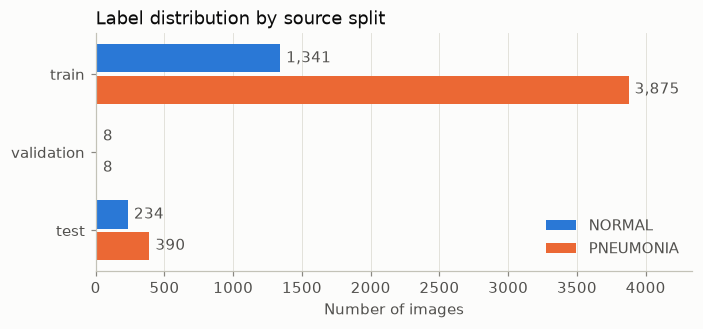

In [4]:
fig, ax = plt.subplots(figsize=(7, 2.8))
y = np.arange(len(SPLIT_ORDER))
h = 0.36
for k, label in enumerate(LABELS):
    vals = counts[label].to_numpy()
    bars = ax.barh(y + (k - 0.5) * (h + 0.04), vals, height=h, color=COLORS[label], label=label)
    ax.bar_label(bars, labels=[f"{v:,}" for v in vals], padding=4, color=INK_2)
ax.set_yticks(y, SPLIT_ORDER)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of images")
ax.set_title("Label distribution by source split")
ax.legend(loc="lower right")
ax.margins(x=0.12)
save(fig, "label_distribution_source")
plt.show()

**Nhận xét.**
- Mất cân bằng: train có ~3 PNEUMONIA cho 1 NORMAL; test cân bằng hơn (62,5% PNEUMONIA).
- Split `validation` gốc chỉ có 16 ảnh — quá ít để làm early stopping, nên `split.py` gộp nó vào train và tách val mới (mục 6).

## 2. Định dạng và chế độ màu

Tất cả là JPEG. Phần lớn ảnh lưu dạng xám (`L`), một nhóm lưu dạng `RGB` — dù nội dung vẫn là ảnh xám (`color = 0`).

In [5]:
print("Formats:", validation["format"].value_counts().to_dict())
print("Images with real color content:", int(validation["color"].sum()))
pd.crosstab([validation["split"], validation["label_name"]], validation["mode"]).reindex(SPLIT_ORDER, level=0)

Formats: {'JPEG': 5856}
Images with real color content: 0


mode                      L  RGB
split      label_name           
train      NORMAL      1341    0
           PNEUMONIA   3592  283
validation NORMAL         8    0
           PNEUMONIA      8    0
test       NORMAL       234    0
           PNEUMONIA    390    0

**Nhận xét.** **Toàn bộ 283 ảnh RGB là PNEUMONIA** và đều nằm trong split train gốc. Mục 3 và 4 cho thấy đây là một nhóm ảnh có nguồn gốc riêng.

## 3. Kích thước ảnh

In [6]:
size_summary = validation.assign(aspect_ratio=validation["width"] / validation["height"]).groupby(
    ["label_name", "mode"]
)[["width", "height", "aspect_ratio"]].median().round(2)
size_summary["n"] = validation.groupby(["label_name", "mode"]).size()
size_summary

width  height  aspect_ratio     n
label_name mode                                    
NORMAL     L     1654.0  1323.0          1.23  1583
PNEUMONIA  L     1184.0   792.0          1.48  3990
           RGB    759.0   467.0          1.70   283

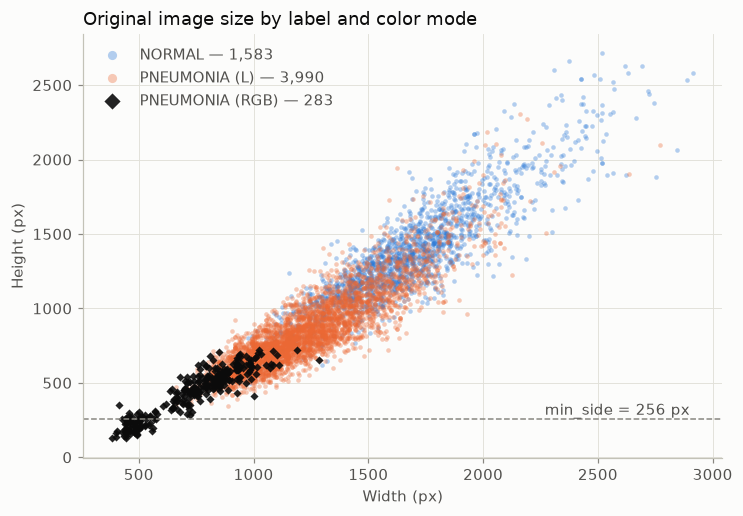

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5))
v = validation
groups = [
    ("NORMAL", v[v["label_name"] == "NORMAL"], "o", COLORS["NORMAL"]),
    ("PNEUMONIA (L)", v[(v["label_name"] == "PNEUMONIA") & (v["mode"] == "L")], "o", COLORS["PNEUMONIA"]),
    ("PNEUMONIA (RGB)", v[v["mode"] == "RGB"], "D", INK),
]
for name, g, marker, color in groups:
    ax.scatter(g["width"], g["height"], s=9 if marker == "o" else 14, marker=marker, color=color,
               alpha=0.35 if marker == "o" else 0.9, linewidths=0, label=f"{name} — {len(g):,}")
vcfg = cfg["validate"]
ax.axhline(vcfg["min_side"], color=MUTED, linewidth=1, linestyle="--")
ax.text(2900, vcfg["min_side"] + 30, f"min_side = {vcfg['min_side']} px", color=INK_2, ha="right")
ax.set_xlabel("Width (px)")
ax.set_ylabel("Height (px)")
ax.set_title("Original image size by label and color mode")
ax.legend(loc="upper left", markerscale=2)
save(fig, "image_sizes")
plt.show()

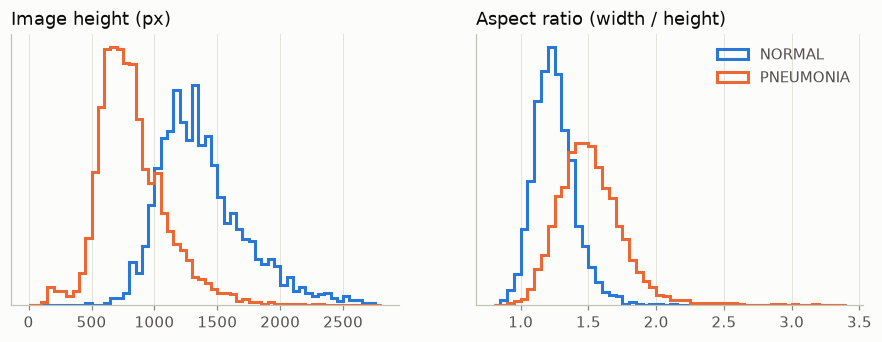

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=False)
bins_h = np.linspace(0, 2800, 57)
bins_ar = np.linspace(0.8, 3.4, 53)
ar = validation["width"] / validation["height"]
for label in LABELS:
    m = validation["label_name"] == label
    axes[0].hist(validation.loc[m, "height"], bins=bins_h, histtype="step", linewidth=2, color=COLORS[label],
                 density=True, label=label)
    axes[1].hist(ar[m], bins=bins_ar, histtype="step", linewidth=2, color=COLORS[label], density=True, label=label)
axes[0].set_title("Image height (px)")
axes[1].set_title("Aspect ratio (width / height)")
for ax in axes:
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[1].legend()
save(fig, "height_aspect_by_label")
plt.show()

**Nhận xét.**
- Ảnh NORMAL có độ phân giải cao hơn rõ rệt (chiều cao trung vị ~1.300 px so với ~800 px ở PNEUMONIA xám) và vuông hơn.
- Nhóm RGB (hình thoi đen) nằm tách biệt ở góc dưới: thấp, rộng. 58 ảnh dưới ngưỡng `min_side`, 27 ảnh có tỉ lệ khung > 2,5 — gần như tất cả thuộc nhóm này.
- Kích thước và tỉ lệ khung là tín hiệu **liên quan đến nhãn nhưng không liên quan đến bệnh** → rủi ro mô hình học đường tắt.

## 4. Ảnh mẫu

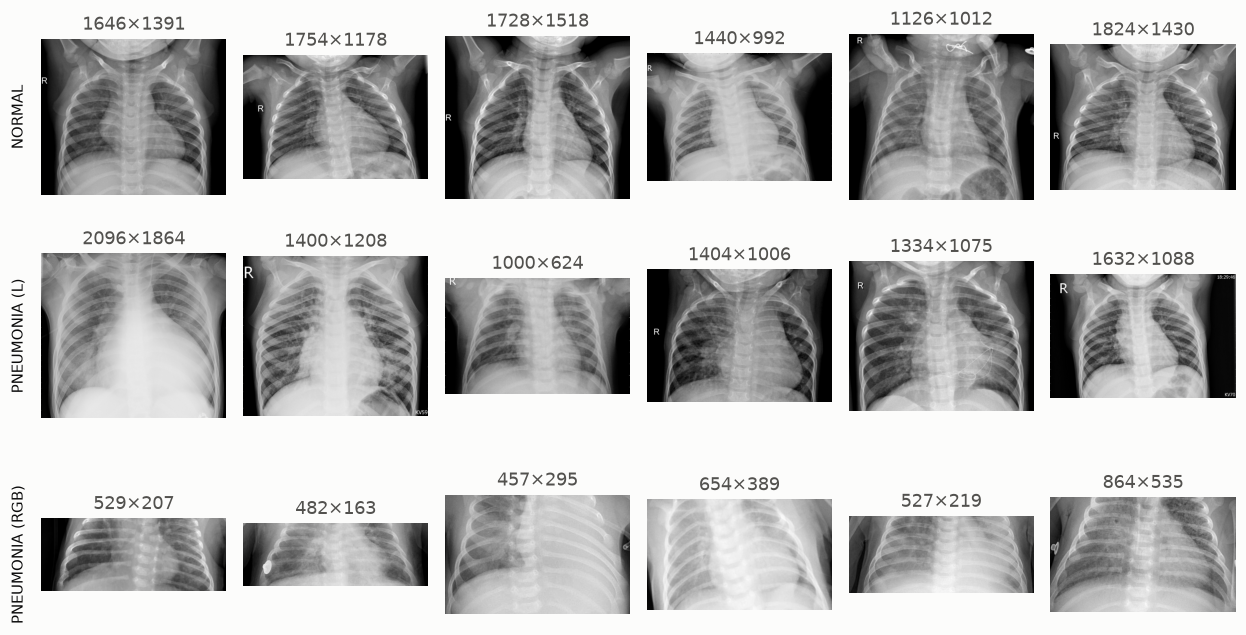

In [9]:
def show_grid(rows, titles, n=6, height=2.1, seed=0, name=None):
    fig, axes = plt.subplots(len(rows), n, figsize=(n * 1.9, len(rows) * height), squeeze=False)
    for r, (df, title) in enumerate(zip(rows, titles)):
        sample = df.sample(min(n, len(df)), random_state=seed)
        for c in range(n):
            ax = axes[r, c]
            ax.axis("off")
            if c >= len(sample):
                continue
            row = sample.iloc[c]
            with Image.open(row["path"]) as img:
                ax.imshow(img.convert("L"), cmap="gray")
                ax.set_title(f"{img.width}×{img.height}", color=INK_2, loc="center")
        axes[r, 0].text(-0.08, 0.5, title, transform=axes[r, 0].transAxes, rotation=90, ha="right",
                        va="center", color=INK)
    fig.tight_layout()
    if name:
        save(fig, name)
    plt.show()


v = validation
show_grid(
    [v[(v["split"] == "train") & (v["label_name"] == "NORMAL")],
     v[(v["split"] == "train") & (v["label_name"] == "PNEUMONIA") & (v["mode"] == "L")],
     v[v["mode"] == "RGB"]],
    ["NORMAL", "PNEUMONIA (L)", "PNEUMONIA (RGB)"],
    name="samples",
)

**Nhận xét.** Ảnh NORMAL và PNEUMONIA xám là phim đầy đủ: thấy vai, xương đòn, cơ hoành, thường có ký hiệu "R". Ảnh RGB bị **cắt sát vùng phổi**, không có vai và ký hiệu; ảnh nặng nhất chỉ là một dải ngang vài xương sườn. Dưới đây là các ảnh bị gắn cờ `too_small` / `extreme_aspect`:

60 flagged images: {('PNEUMONIA', 'L'): 1, ('PNEUMONIA', 'RGB'): 59}


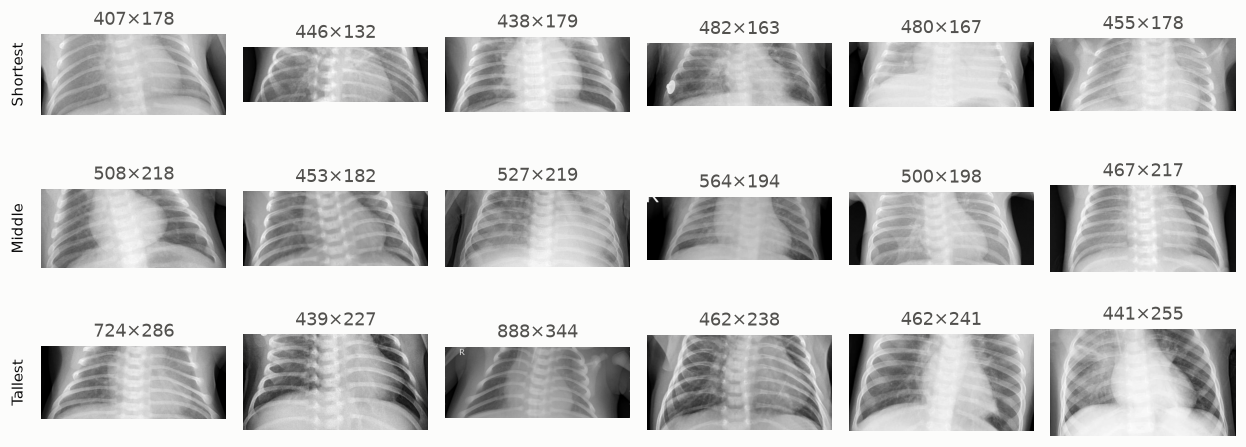

In [10]:
flagged = validation[validation["too_small"] | validation["extreme_aspect"]].sort_values("height")
print(f"{len(flagged)} flagged images:", flagged.groupby(["label_name", "mode"]).size().to_dict())
k = len(flagged) // 3
thirds = [flagged.iloc[:k], flagged.iloc[k:2 * k], flagged.iloc[2 * k:]]
show_grid(thirds, ["Shortest", "Middle", "Tallest"], n=6, height=1.5, name="flagged_strips")

**Quyết định (D3 trong `docs/decisions.md`).** Loại cả 283 ảnh RGB khỏi train/val qua `exclude_flags` trong `configs/data.yaml`; test giữ nguyên.

## 5. Ảnh trùng và nhóm bệnh nhân

`dedup.py` gom ảnh vào `group_id` nếu trùng pHash (256 bit, Hamming ≤ 20) hoặc cùng mã bệnh nhân trong tên file (`person{N}_{bacteria|virus}`, `IM-N`, `NORMAL2-IM-N`).

In [11]:
dedup_summary = json.loads((report_dir / "dedup_summary.json").read_text())
nd, gr = dedup_summary["near_duplicates"], dedup_summary["groups"]
print(f"Near-duplicate pairs: {nd['n_pairs']} (exact copies: {nd['n_exact_pairs']}, "
      f"different labels: {nd['n_cross_label_pairs']}) by split: {nd['pairs_by_split']}")
print(f"Patients: {dedup_summary['patients']['n_patients']:,}, groups: {gr['n_groups']:,}, "
      f"groups spanning splits: {gr['n_spanning_splits']}")

Near-duplicate pairs: 34 (exact copies: 34, different labels: 0) by split: {'train+train': 28, 'test+test': 6}
Patients: 4,097, groups: 4,096, groups spanning splits: 0


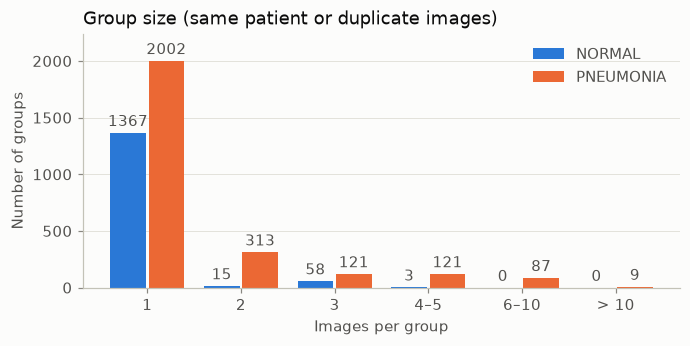

In [12]:
sizes = dedup.drop_duplicates("group_id").merge(
    dedup.groupby("group_id")["label_name"].first().rename("group_label"), on="group_id"
)
bins = [1, 2, 3, 4, 6, 11, 100]
bin_labels = ["1", "2", "3", "4–5", "6–10", "> 10"]
sizes["bucket"] = pd.cut(sizes["group_size"], bins=bins, right=False, labels=bin_labels)
table = sizes.groupby(["bucket", "group_label"], observed=False).size().unstack(fill_value=0)[LABELS]

fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(bin_labels))
w = 0.38
for k, label in enumerate(LABELS):
    bars = ax.bar(x + (k - 0.5) * (w + 0.03), table[label], width=w, color=COLORS[label], label=label)
    ax.bar_label(bars, padding=2, color=INK_2)
ax.set_xticks(x, bin_labels)
ax.set_xlabel("Images per group")
ax.set_ylabel("Number of groups")
ax.set_title("Group size (same patient or duplicate images)")
ax.margins(y=0.12)
ax.grid(axis="x", visible=False)
ax.legend()
save(fig, "group_sizes")
plt.show()

**Nhận xét.**
- 34 cặp trùng đều là bản sao giống từng byte, không cặp nào khác nhãn, **không cặp nào giữa train và test**.
- Phần lớn bệnh nhân NORMAL chỉ có 1 ảnh; bệnh nhân PNEUMONIA thường có nhiều ảnh (tới 30). Nếu chia ngẫu nhiên theo ảnh, ảnh cùng bệnh nhân sẽ rơi vào cả train và val → AUC val bị thổi phồng. Vì vậy `split.py` chia theo nhóm.

## 6. Phân chia cuối cùng (`splits.csv`)

In [13]:
final = splits.groupby(["split", "label_name"]).size().unstack(fill_value=0).reindex(["train", "val", "test"])[LABELS]
final["total"] = final.sum(axis=1)
final["pneumonia_ratio"] = (final["PNEUMONIA"] / final["total"]).map("{:.1%}".format)
final["groups"] = splits.groupby("split")["group_id"].nunique()
excluded = json.loads((report_dir / "split_summary.json").read_text())["excluded_from_train_pool"]
print("Excluded from train pool:", excluded)
print("Groups spanning splits:", int((splits.groupby("group_id")["split"].nunique() > 1).sum()))
final

Excluded from train pool: {'too_small': 58, 'extreme_aspect': 26, 'rgb_mode': 283, 'flagged_total': 283, 'exact_duplicate': 26}
Groups spanning splits: 0


label_name,NORMAL,PNEUMONIA,total,pneumonia_ratio,groups
split,,,,,
train,1155,3064,4219,72.6%,2997
val,193,511,704,72.6%,501
test,234,390,624,62.5%,427


## 7. Thống kê chất lượng ảnh trên train (tham chiếu giám sát)

Tính bằng `cxr.monitoring.image_stats` sau `prepare_gray` (xám, 224×224) — cùng hàm mà API sẽ dùng để giám sát ảnh đầu vào. Phân vị lưu trong `data/reference/stats.json`.

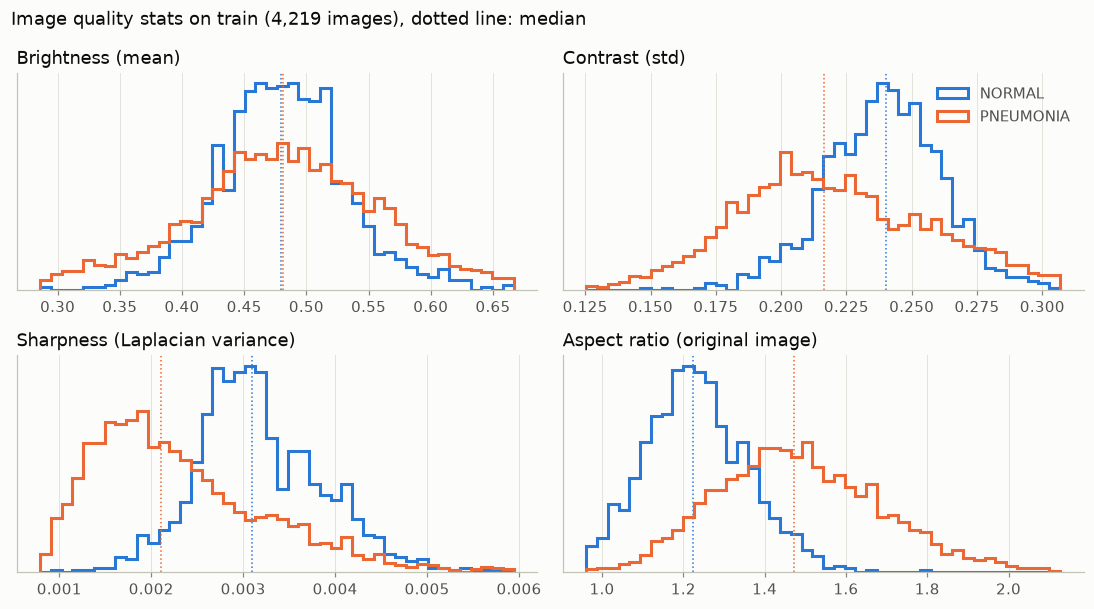

In [14]:
metrics = [("brightness", "Brightness (mean)"), ("contrast", "Contrast (std)"),
           ("blur", "Sharpness (Laplacian variance)"), ("aspect_ratio", "Aspect ratio (original image)")]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.6))
for ax, (col, title) in zip(axes.flat, metrics):
    lo, hi = train_stats[col].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 45)
    for label in LABELS:
        vals = train_stats.loc[train_stats["label_name"] == label, col]
        ax.hist(vals, bins=bins, histtype="step", linewidth=2, color=COLORS[label], density=True, label=label)
        ax.axvline(vals.median(), color=COLORS[label], linewidth=1, linestyle=":")
    ax.set_title(title)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0, 1].legend()
fig.suptitle(f"Image quality stats on train ({len(train_stats):,} images), dotted line: median",
             x=0.01, ha="left", color=INK)
fig.tight_layout()
save(fig, "quality_stats_train")
plt.show()

In [15]:
rows = []
for name in ["brightness", "contrast", "blur", "aspect_ratio", "height"]:
    row = {"metric": name}
    for label in LABELS:
        row[f"{label} median"] = reference["stats_by_label"][label][name]["quantiles"]["p50"]
    q = reference["stats"][name]["quantiles"]
    row["all p1"], row["all p99"] = q["p1"], q["p99"]
    rows.append(row)
pd.DataFrame(rows).set_index("metric").round(4)

,NORMAL median,PNEUMONIA median,all p1,all p99
metric,,,,
brightness,0.4799,0.4812,0.2999,0.6546
contrast,0.2400,0.2163,0.1410,0.3025
blur,0.0031,0.0021,0.0009,0.0055
aspect_ratio,1.2244,1.4728,0.9921,2.0000
height,1330.0000,803.0000,488.0000,2108.1000


**Nhận xét.**
- Độ sáng gần như giống nhau giữa hai nhãn — tốt.
- Ảnh NORMAL **nét hơn** và **tương phản cao hơn**, tỉ lệ khung vuông hơn — hệ quả của độ phân giải gốc cao hơn. Đây là giới hạn của dữ liệu Kermany không lọc được; cần nêu trong `data_card.md` / `model_card.md`.
- Khoảng p1–p99 trên toàn train là cơ sở để `drift.py` gắn cờ ảnh đầu vào bất thường.

## 8. Kiểm tra tiền xử lý (`transforms.py`)

Cùng một ảnh qua: hai chính sách resize (`squash`, `center_crop`) và vài lần augment của train (xoay ±10°, scale 0,9–1,1, dịch 5%, **không lật ngang**).

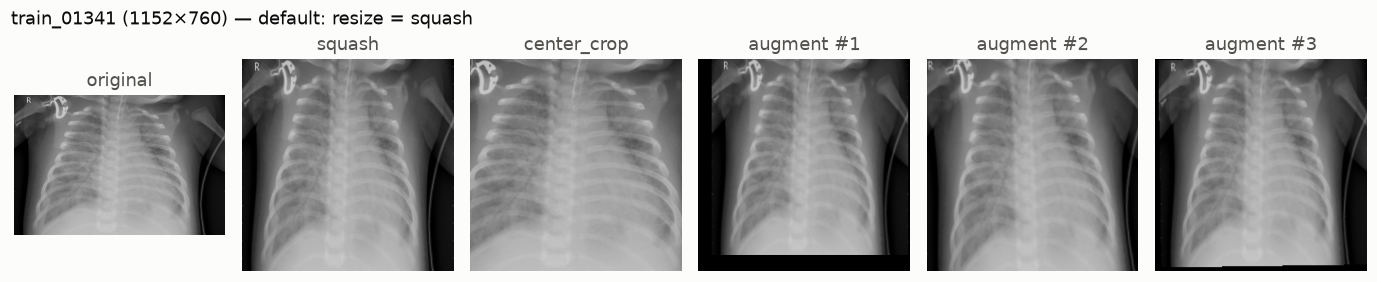

In [16]:
import torch

row = splits[(splits["split"] == "train") & (splits["label_name"] == "PNEUMONIA")].iloc[0]
img = Image.open(row["path"])
mean = torch.tensor(cfg["image"]["mean"]).view(3, 1, 1)
std = torch.tensor(cfg["image"]["std"]).view(3, 1, 1)
train_tf = build_transforms(cfg, train=True)
torch.manual_seed(0)

panels = [("original", img.convert("L")),
          ("squash", prepare_gray(img, {**cfg["image"], "resize": "squash"})),
          ("center_crop", prepare_gray(img, {**cfg["image"], "resize": "center_crop"}))]
panels += [(f"augment #{i + 1}", ((train_tf(img) * std + mean)[0]).clamp(0, 1).numpy()) for i in range(3)]

fig, axes = plt.subplots(1, len(panels), figsize=(2.1 * len(panels), 2.6))
for ax, (title, im) in zip(axes, panels):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255 if isinstance(im, Image.Image) else 1)
    ax.set_title(title, loc="center", color=INK_2)
    ax.axis("off")
fig.suptitle(f"{row['image_id']} ({img.width}×{img.height}) — default: resize = {cfg['image']['resize']}",
             x=0.01, ha="left", color=INK)
fig.tight_layout()
save(fig, "transforms")
plt.show()

**Nhận xét.** `squash` giữ trọn lồng ngực nhưng ép ảnh rộng thành vuông; `center_crop` giữ tỉ lệ nhưng có thể cắt mép phổi ở ảnh rộng. Mặc định đang là `squash` — có thể so sánh hai chính sách bằng baseline (đổi `image.resize` trong config).

## Tóm tắt

| Vấn đề | Xử lý |
| :-- | :-- |
| Split `validation` gốc chỉ 16 ảnh | Gộp vào train, tách val ~14% bằng `StratifiedGroupKFold` |
| Nhiều ảnh cùng bệnh nhân | Chia theo `group_id` — không nhóm nào nằm ở 2 split |
| 34 cặp ảnh trùng (không cặp nào train–test) | Bỏ bản trùng trong train/val; giữ nguyên test |
| 283 ảnh RGB bị cắt, chỉ ở PNEUMONIA | Loại khỏi train/val (D3) |
| NORMAL có độ phân giải / độ nét cao hơn | Không lọc được → nêu trong data card / model card |
| Mất cân bằng nhãn (~73% PNEUMONIA ở train) | Class weight trong loss; AUC là chỉ số chính |